# Model testing
This file is for testing and creating the best ml model for trading predictions and building it in python then implement in cpp

## Main Idea
To find the best model fit... the objective of the model is to predict if the currency pair will increase over the next 15min ? and make a reccomandation to either trade or not 

In [61]:
import math 
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os 
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix, log_loss
import joblib

In [62]:
data_eur_usd = pd.read_csv("../data/ohlc_eur_usd.csv")
data_aud_usd = pd.read_csv("../data/ohlc_aud_usd.csv")

In [63]:
print(data_eur_usd.head(), '\n\n')
print(data_eur_usd.info(), '\n\n')

                        date     pair      open      high       low     close
0  2024-11-20 17:15:00-05:00  EUR_USD  1.054275  1.054290  1.054240  1.054260
1  2024-11-20 17:16:00-05:00  EUR_USD  1.054260  1.054285  1.054260  1.054270
2  2024-11-20 17:17:00-05:00  EUR_USD  1.054270  1.054275  1.054225  1.054250
3  2024-11-20 17:18:00-05:00  EUR_USD  1.054250  1.054270  1.054240  1.054265
4  2024-11-20 17:19:00-05:00  EUR_USD  1.054265  1.054265  1.054245  1.054250 


<class 'pandas.DataFrame'>
RangeIndex: 74810 entries, 0 to 74809
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    74810 non-null  str    
 1   pair    74810 non-null  str    
 2   open    74810 non-null  float64
 3   high    74810 non-null  float64
 4   low     74810 non-null  float64
 5   close   74810 non-null  float64
dtypes: float64(4), str(2)
memory usage: 3.4 MB
None 




In [64]:
data_eur_usd.describe()

,open,high,low,close
count,74810.000000,74810.000000,74810.000000,74810.000000
mean,1.041574,1.041656,1.041492,1.041574
std,0.009100,0.009099,0.009102,0.009100
min,1.017980,1.018810,1.017755,1.017980
25%,1.035300,1.035376,1.035230,1.035300
50%,1.041290,1.041375,1.041200,1.041290
75%,1.049315,1.049380,1.049240,1.049315
max,1.062195,1.062990,1.062120,1.062195


In [65]:
print(data_aud_usd.head(), '\n\n')
print(data_aud_usd.info(), '\n\n')

                        date     pair      open      high       low     close
0  2024-11-20 22:15:00+00:00  AUD_USD  0.650425  0.650435  0.650380  0.650410
1  2024-11-20 22:16:00+00:00  AUD_USD  0.650410  0.650415  0.650380  0.650395
2  2024-11-20 22:17:00+00:00  AUD_USD  0.650395  0.650430  0.650395  0.650415
3  2024-11-20 22:18:00+00:00  AUD_USD  0.650415  0.650445  0.650415  0.650440
4  2024-11-20 22:19:00+00:00  AUD_USD  0.650440  0.650440  0.650440  0.650440 


<class 'pandas.DataFrame'>
RangeIndex: 725122 entries, 0 to 725121
Data columns (total 6 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    725122 non-null  str    
 1   pair    725122 non-null  str    
 2   open    725122 non-null  float64
 3   high    725122 non-null  float64
 4   low     725122 non-null  float64
 5   close   725122 non-null  float64
dtypes: float64(4), str(2)
memory usage: 33.2 MB
None 




In [66]:
data_aud_usd.describe()

,open,high,low,close
count,725122.000000,725122.000000,725122.000000,725122.000000
mean,0.708335,0.708396,0.708273,0.708335
std,0.117011,0.117017,0.117005,0.117011
min,0.592235,0.592345,0.591420,0.592235
25%,0.648115,0.648185,0.648055,0.648115
50%,0.669320,0.669370,0.669270,0.669320
75%,0.707190,0.707255,0.707129,0.707190
max,1.062195,1.062990,1.062120,1.062195


# Graphing data 

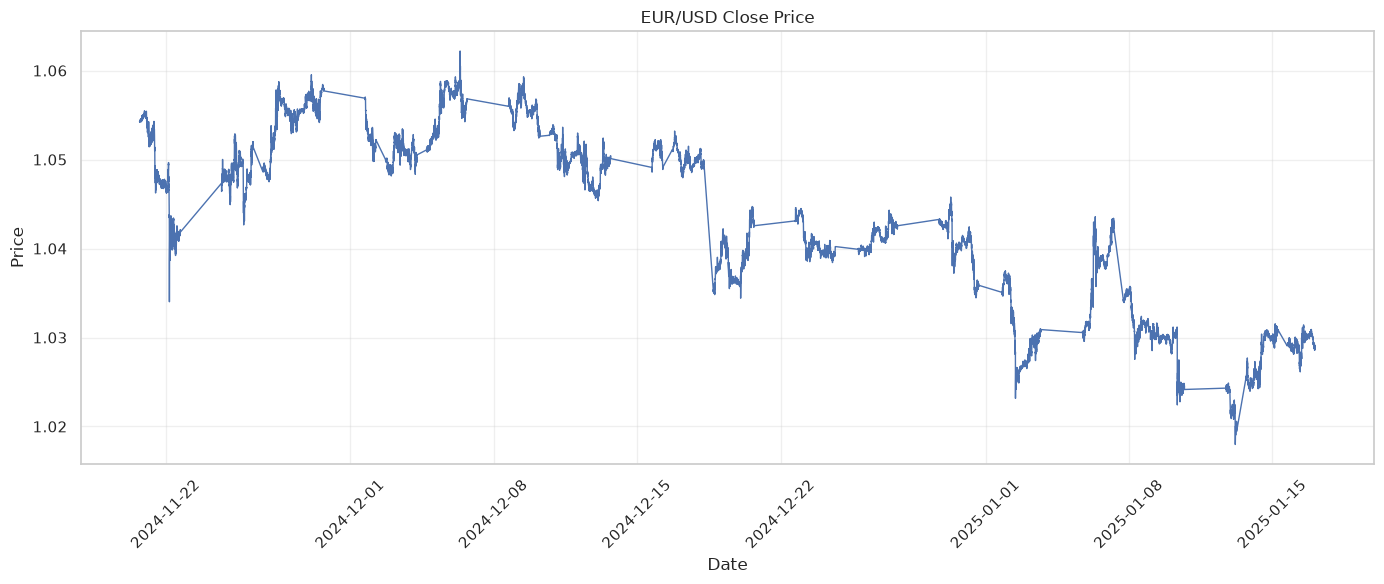

In [67]:
data_eur_usd['date'] = pd.to_datetime(data_eur_usd['date'])
data_sample = data_eur_usd.head(50000)
plt.figure(figsize=(14, 6))
plt.plot(data_sample['date'], data_sample['close'], linewidth=1)
plt.title('EUR/USD Close Price')
plt.xlabel('Date')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

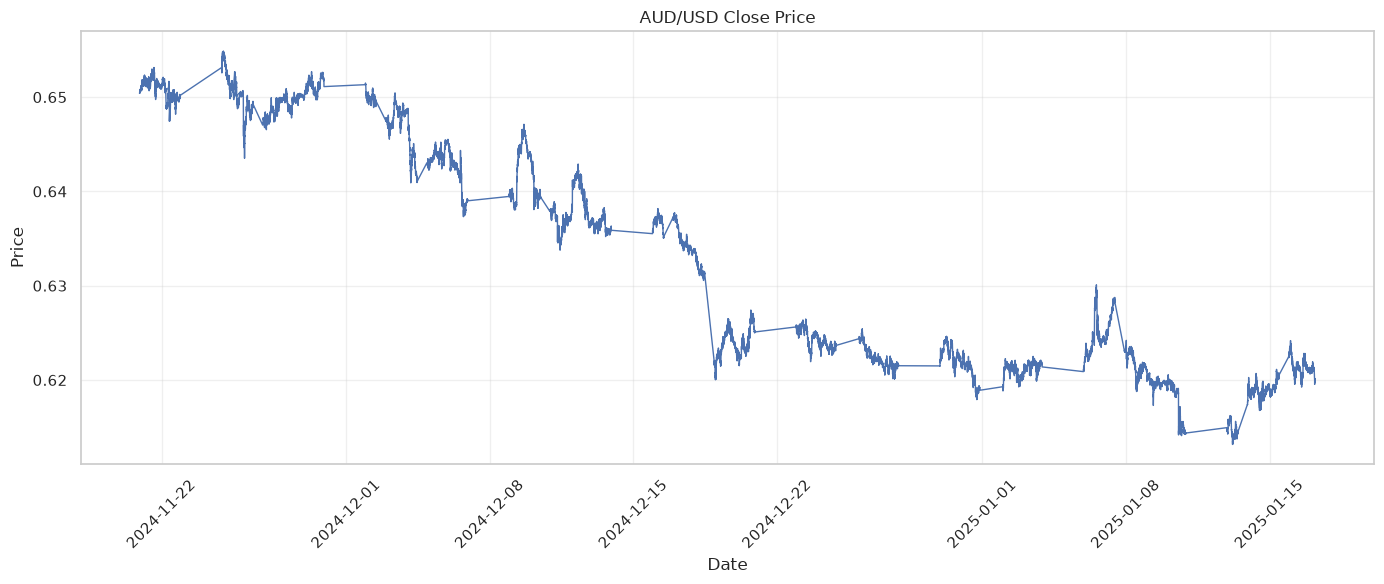

In [68]:
data_aud_usd['date'] = pd.to_datetime(data_aud_usd['date'])
data_sample = data_aud_usd.head(50000)
plt.figure(figsize=(14, 6))
plt.plot(data_sample['date'], data_sample['close'], linewidth=1)
plt.title('AUD/USD Close Price')
plt.xlabel('Date')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [69]:
sns.set_theme(style="whitegrid")

df_eur_usd = data_eur_usd.copy()

# Convert dates
df_eur_usd['date'] = pd.to_datetime(df_eur_usd['date'], errors='coerce')

# Convert OHLC columns to numeric
price_cols = ['open', 'high', 'low', 'close']

for col in price_cols:
    df_eur_usd[col] = pd.to_numeric(df_eur_usd[col], errors='coerce')

print("Dataset shape:", df_eur_usd.shape)
print("\nData types:")
print(df_eur_usd.dtypes)

print("\nMissing values:")
print(df_eur_usd.isnull().sum())

print("\nSummary statistics:")
print(df_eur_usd.describe())

Dataset shape: (74810, 6)

Data types:
date     datetime64[us, UTC-05:00]
pair                           str
open                       float64
high                       float64
low                        float64
close                      float64
dtype: object

Missing values:
date     0
pair     0
open     0
high     0
low      0
close    0
dtype: int64

Summary statistics:
               open          high           low         close
count  74810.000000  74810.000000  74810.000000  74810.000000
mean       1.041574      1.041656      1.041492      1.041574
std        0.009100      0.009099      0.009102      0.009100
min        1.017980      1.018810      1.017755      1.017980
25%        1.035300      1.035376      1.035230      1.035300
50%        1.041290      1.041375      1.041200      1.041290
75%        1.049315      1.049380      1.049240      1.049315
max        1.062195      1.062990      1.062120      1.062195


In [70]:
sns.set_theme(style="whitegrid")

df_aud_usd = data_aud_usd.copy()

# Convert dates
df_aud_usd['date'] = pd.to_datetime(df_aud_usd['date'], errors='coerce')

# Convert OHLC columns to numeric
price_cols = ['open', 'high', 'low', 'close']

for col in price_cols:
    df_aud_usd[col] = pd.to_numeric(df_aud_usd[col], errors='coerce')

print("Dataset shape:", df_aud_usd.shape)
print("\nData types:")
print(df_aud_usd.dtypes)

print("\nMissing values:")
print(df_aud_usd.isnull().sum())

print("\nSummary statistics:")
print(df_aud_usd.describe())

Dataset shape: (725122, 6)

Data types:
date     datetime64[us, UTC]
pair                     str
open                 float64
high                 float64
low                  float64
close                float64
dtype: object

Missing values:
date     0
pair     0
open     0
high     0
low      0
close    0
dtype: int64

Summary statistics:
                open           high            low          close
count  725122.000000  725122.000000  725122.000000  725122.000000
mean        0.708335       0.708396       0.708273       0.708335
std         0.117011       0.117017       0.117005       0.117011
min         0.592235       0.592345       0.591420       0.592235
25%         0.648115       0.648185       0.648055       0.648115
50%         0.669320       0.669370       0.669270       0.669320
75%         0.707190       0.707255       0.707129       0.707190
max         1.062195       1.062990       1.062120       1.062195


In [71]:
# Keep original data untouched
df_eur_usd = df_eur_usd.dropna(subset=['date', 'pair'] + price_cols)

# Remove duplicate candles
df_eur_usd = df_eur_usd.drop_duplicates(subset=['date', 'pair'])

# Remove invalid prices
df_eur_usd = df_eur_usd[(df_eur_usd[price_cols] > 0).all(axis=1)]

# Validate OHLC relationships
valid_ohlc = (
    (df_eur_usd['high'] >= df_eur_usd[['open', 'close', 'low']].max(axis=1)) &
    (df_eur_usd['low'] <= df_eur_usd[['open', 'close', 'high']].min(axis=1))
)

invalid_count = (~valid_ohlc).sum()
print("Invalid OHLC candles:", invalid_count)

df_eur_usd = df_eur_usd[valid_ohlc].copy()

# Sort chronologically
df_eur_usd = df_eur_usd.sort_values(['pair', 'date']).reset_index(drop=True)

print("\nCleaned dataset:", df_eur_usd.shape)

Invalid OHLC candles: 0

Cleaned dataset: (74810, 6)


In [72]:
# Keep original data untouched
df_aud_usd = df_aud_usd.dropna(subset=['date', 'pair'] + price_cols)

# Remove duplicate candles
df_aud_usd = df_aud_usd.drop_duplicates(subset=['date', 'pair'])

# Remove invalid prices
df_aud_usd = df_aud_usd[(df_aud_usd[price_cols] > 0).all(axis=1)]

# Validate OHLC relationships
valid_ohlc = (
    (df_aud_usd['high'] >= df_aud_usd[['open', 'close', 'low']].max(axis=1)) &
    (df_aud_usd['low'] <= df_aud_usd[['open', 'close', 'high']].min(axis=1))
)

invalid_count = (~valid_ohlc).sum()
print("Invalid OHLC candles:", invalid_count)

df_aud_usd = df_aud_usd[valid_ohlc].copy()

# Sort chronologically
df_aud_usd = df_aud_usd.sort_values(['pair', 'date']).reset_index(drop=True)

print("\nCleaned dataset:", df_aud_usd.shape)

Invalid OHLC candles: 0

Cleaned dataset: (725122, 6)


# Data distrubutions

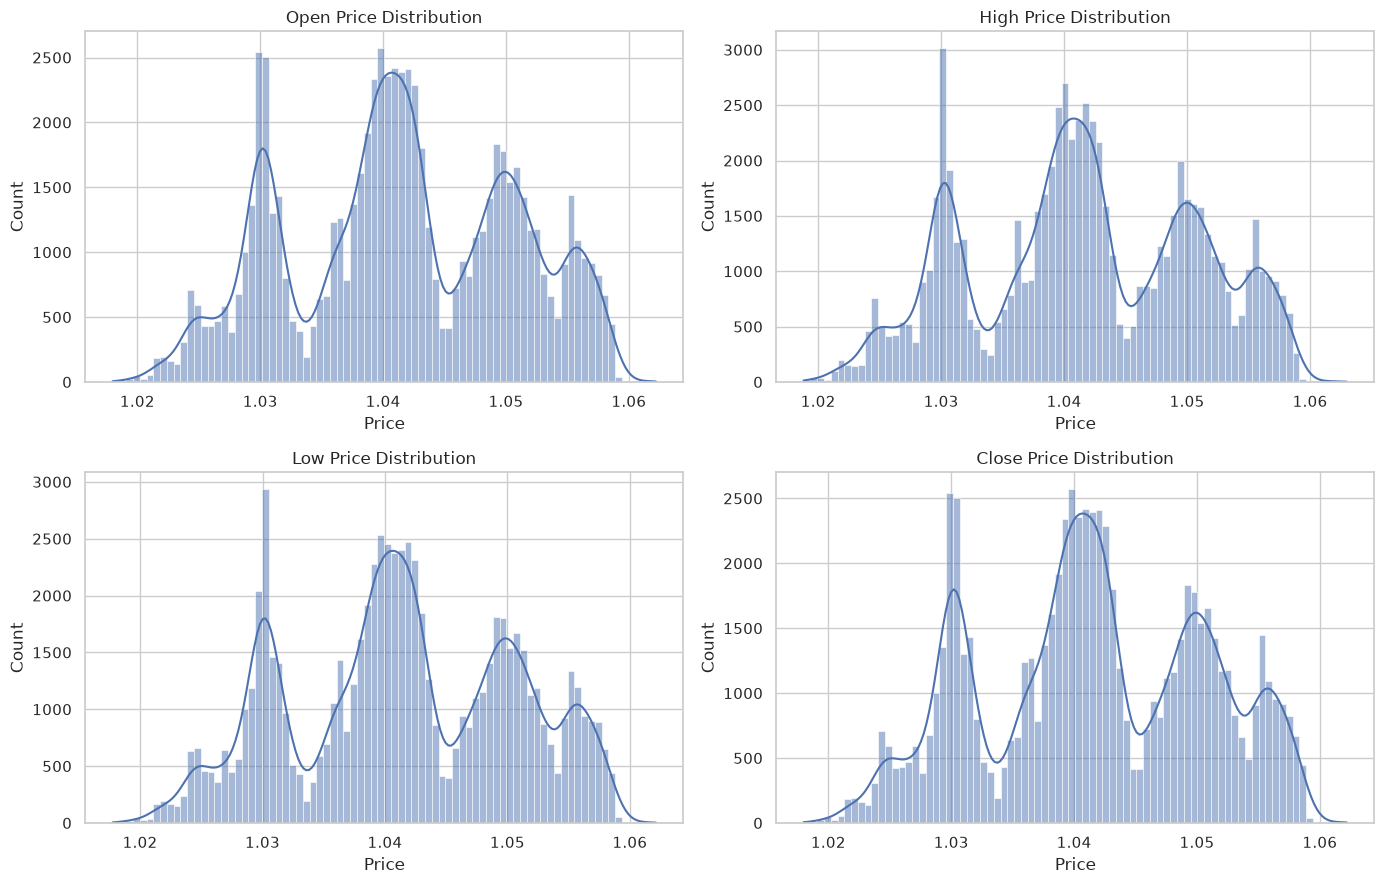

In [73]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for col, ax in zip(price_cols, axes.flatten()):
    sns.histplot(df_eur_usd[col], bins=80, kde=True, ax=ax)
    ax.set_title(f'{col.capitalize()} Price Distribution')
    ax.set_xlabel('Price')

plt.tight_layout()
plt.show()

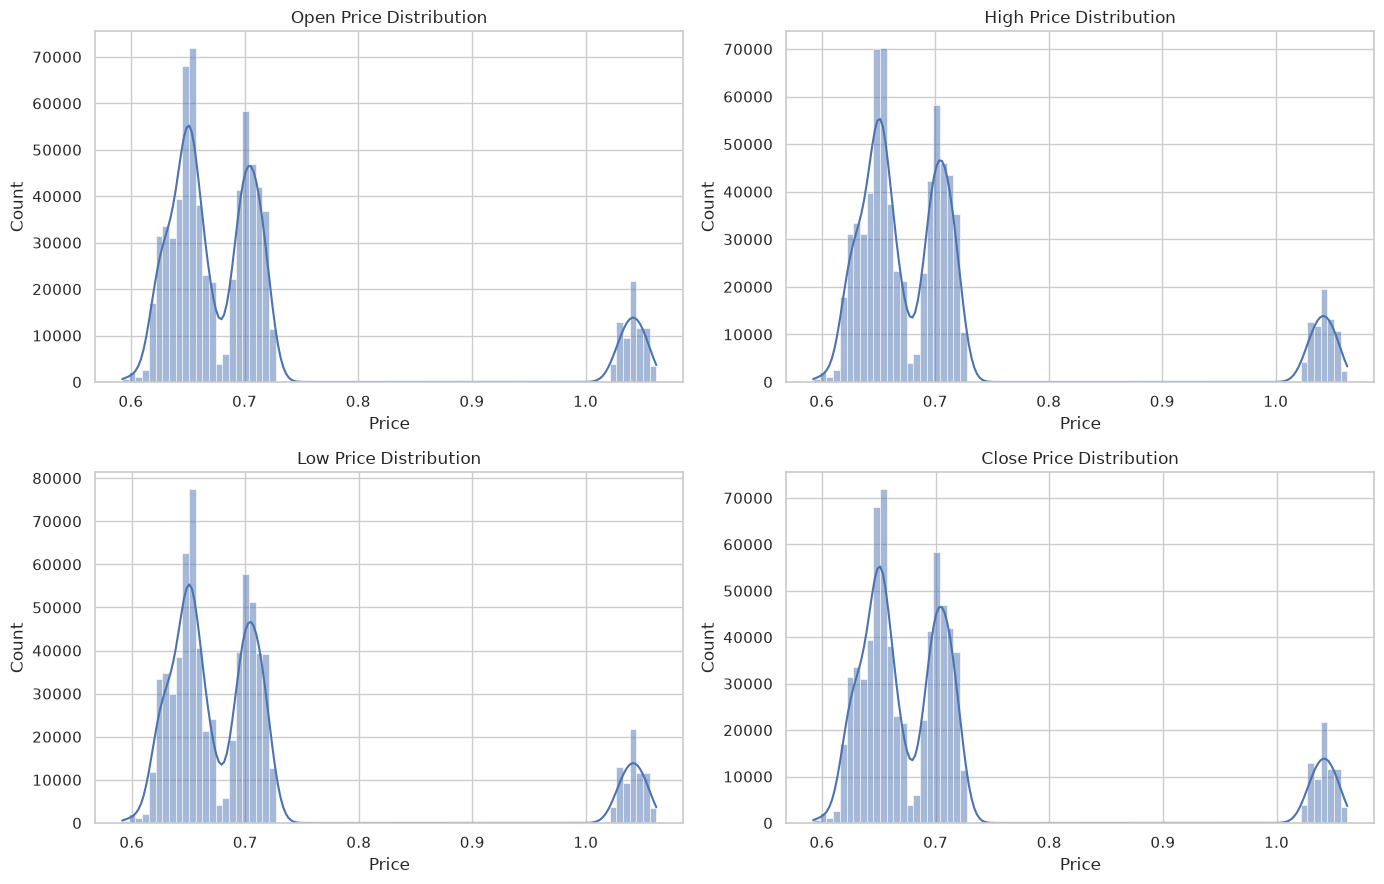

In [74]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for col, ax in zip(price_cols, axes.flatten()):
    sns.histplot(df_aud_usd[col], bins=80, kde=True, ax=ax)
    ax.set_title(f'{col.capitalize()} Price Distribution')
    ax.set_xlabel('Price')

plt.tight_layout()
plt.show()

In [75]:
df_eur_usd['returns'] = df_eur_usd.groupby('pair')['close'].pct_change()

df_eur_usd['log_returns'] = np.log(
    df_eur_usd['close'] / df_eur_usd.groupby('pair')['close'].shift(1)
)

df_eur_usd['candle_body'] = df_eur_usd['close'] - df_eur_usd['open']

df_eur_usd['candle_range'] = df_eur_usd['high'] - df_eur_usd['low']

df_eur_usd['upper_wick'] = (
    df_eur_usd['high'] - df_eur_usd[['open', 'close']].max(axis=1)
)

df_eur_usd['lower_wick'] = (
    df_eur_usd[['open', 'close']].min(axis=1) - df_eur_usd['low']
)

features_eur_usd = [
    'returns',
    'log_returns',
    'candle_body',
    'candle_range',
    'upper_wick',
    'lower_wick'
]

# Remove rows containing NaN or infinite values in the features
df_eur_usd[features_eur_usd] = (
    df_eur_usd[features_eur_usd]
    .replace([np.inf, -np.inf], np.nan)
)


In [76]:
df_aud_usd['returns'] = df_aud_usd.groupby('pair')['close'].pct_change()

df_aud_usd['log_returns'] = np.log(
    df_aud_usd['close'] / df_aud_usd.groupby('pair')['close'].shift(1)
)

df_aud_usd['candle_body'] = df_aud_usd['close'] - df_aud_usd['open']

df_aud_usd['candle_range'] = df_aud_usd['high'] - df_aud_usd['low']

df_aud_usd['upper_wick'] = (
    df_aud_usd['high'] - df_aud_usd[['open', 'close']].max(axis=1)
)

df_aud_usd['lower_wick'] = (
    df_aud_usd[['open', 'close']].min(axis=1) - df_aud_usd['low']
)

features_aud_usd = [
    'returns',
    'log_returns',
    'candle_body',
    'candle_range',
    'upper_wick',
    'lower_wick'
]


# Remove rows containing NaN or infinite values in the features
df_aud_usd[features_aud_usd] = (
    df_aud_usd[features_aud_usd]
    .replace([np.inf, -np.inf], np.nan)
)


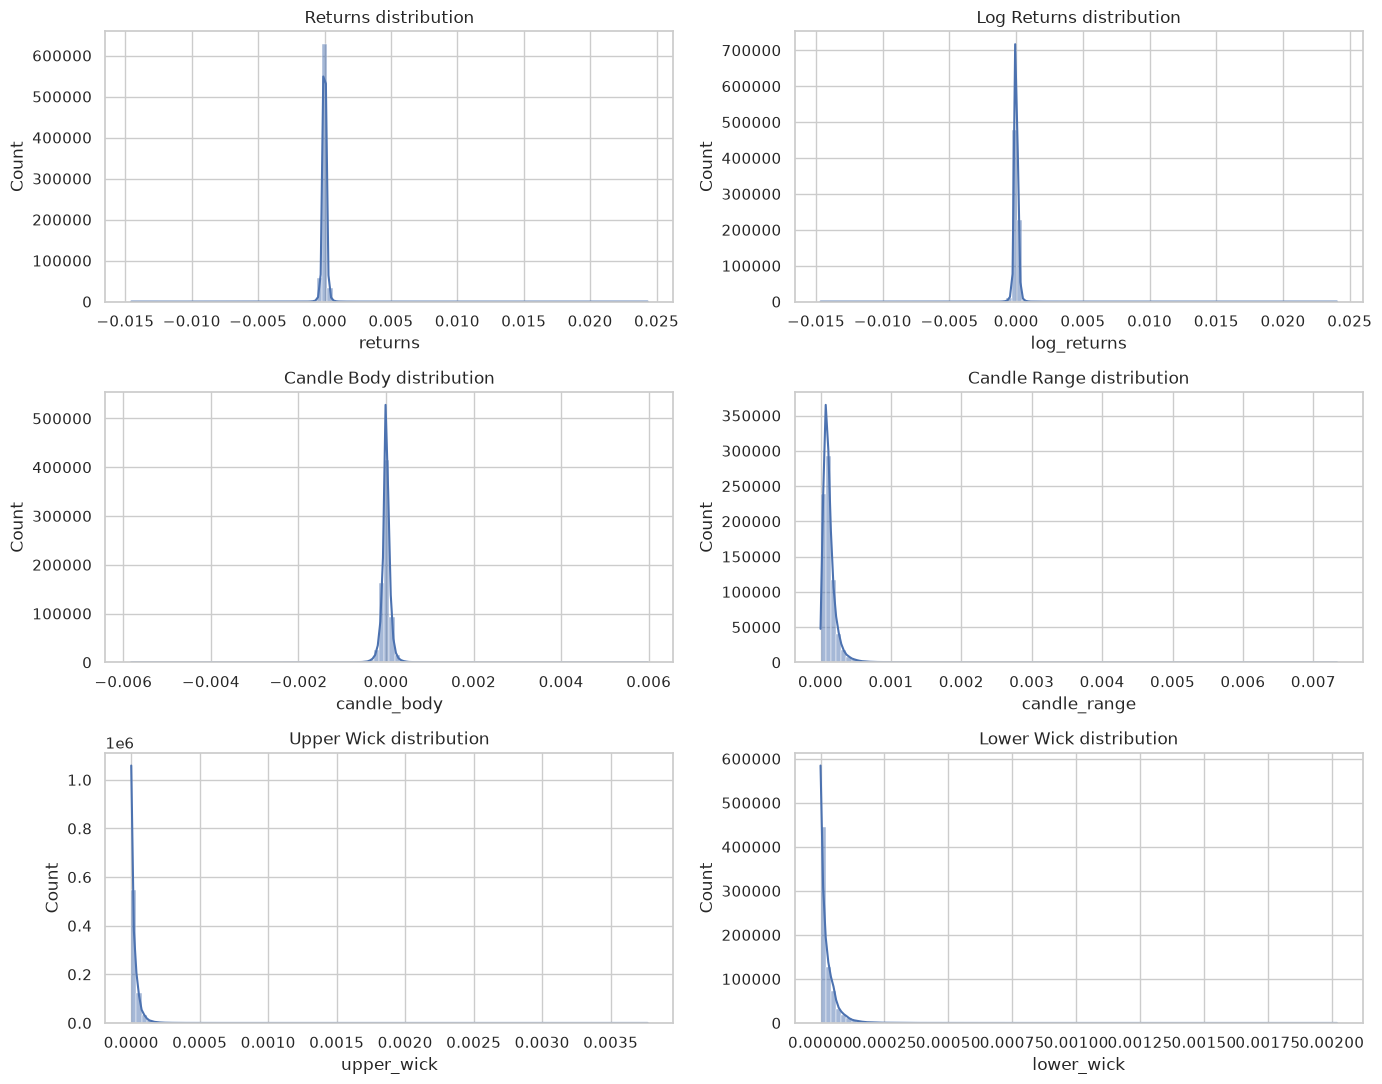

In [77]:
fig, axes = plt.subplots(3, 2, figsize=(14, 11))

for col, ax in zip(features_aud_usd, axes.flatten()):
    sns.histplot(
        df_aud_usd[col].dropna(),
        bins=100,
        kde=True,
        ax=ax
    )
    ax.set_title(f'{col.replace("_", " ").title()} distribution')

plt.tight_layout()
plt.show()

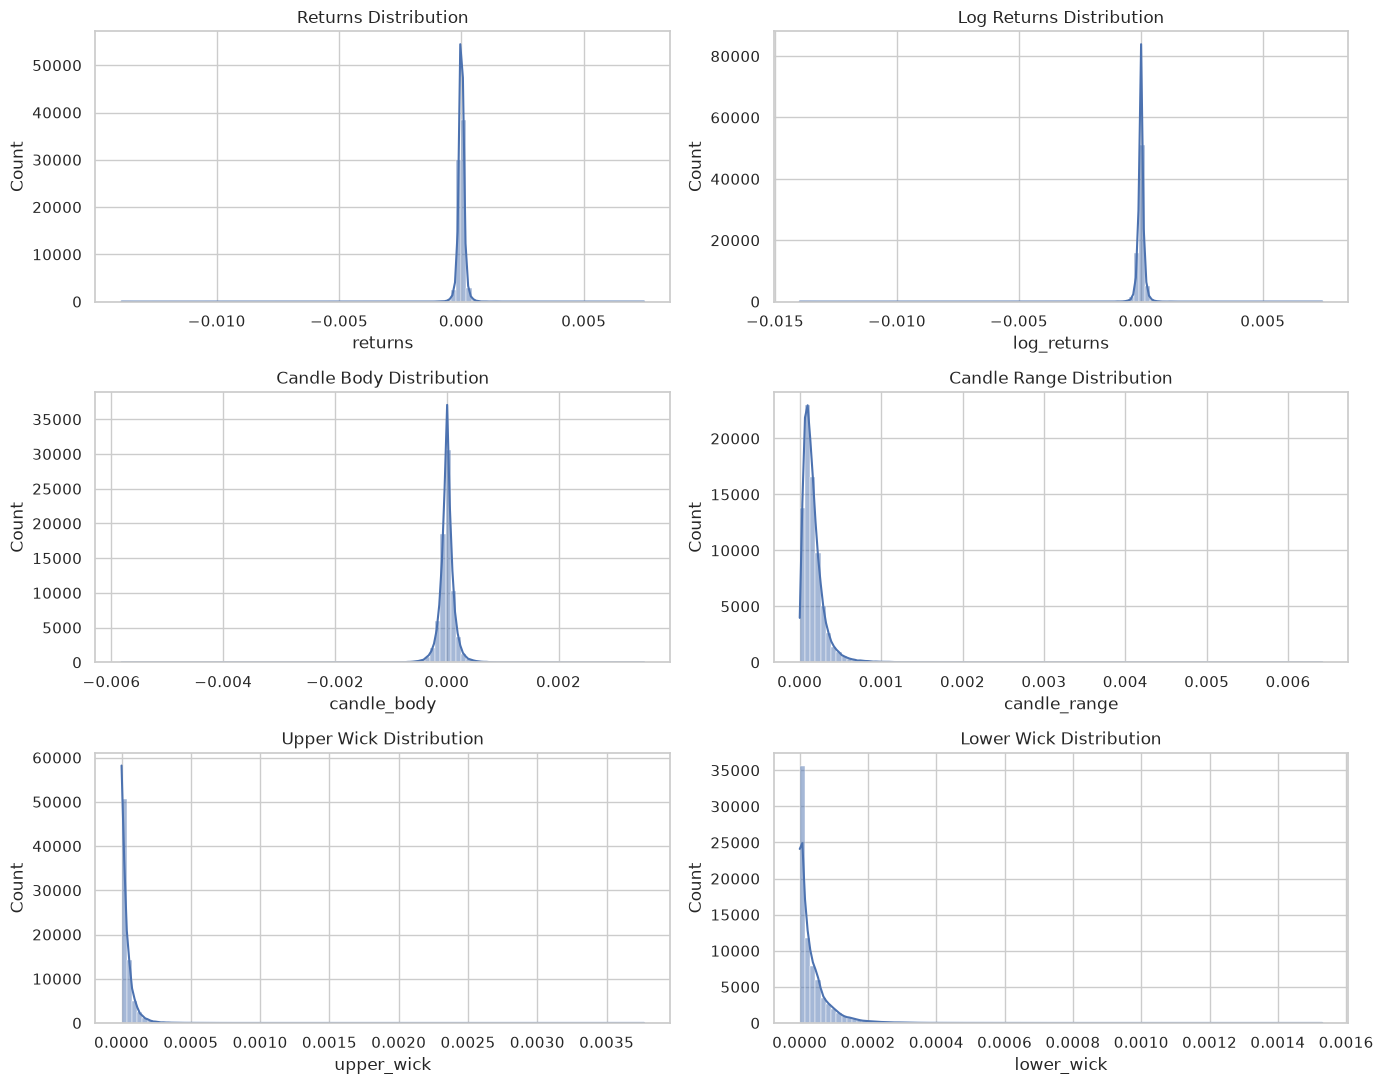

In [78]:
fig, axes = plt.subplots(3, 2, figsize=(14, 11))

for col, ax in zip(features_eur_usd, axes.flatten()):
    sns.histplot(
        df_eur_usd[col].dropna(),
        bins=100,
        kde=True,
        ax=ax
    )
    ax.set_title(f'{col.replace("_", " ").title()} Distribution')

plt.tight_layout()
plt.show()


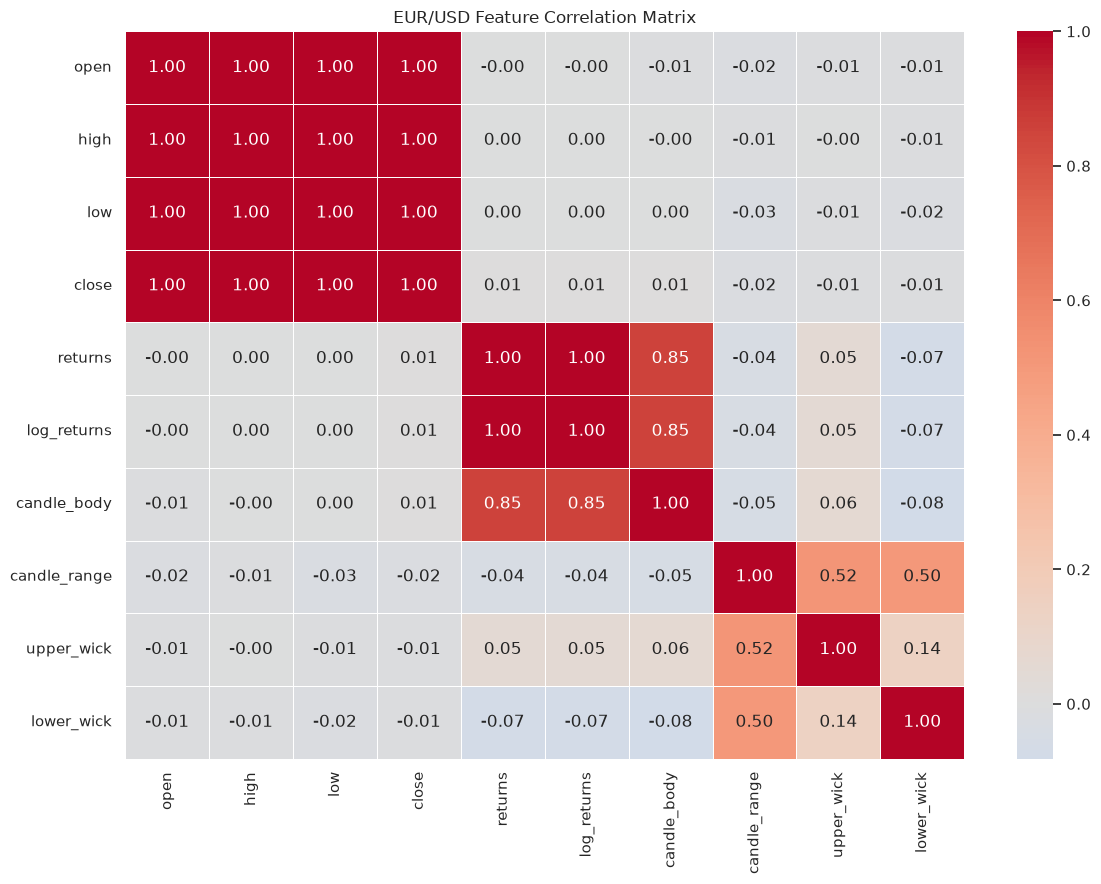

In [79]:
correlation_cols = price_cols + features_eur_usd

corr = df_eur_usd[correlation_cols].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f',
    linewidths=0.5
)

plt.title('EUR/USD Feature Correlation Matrix')
plt.tight_layout()
plt.show()


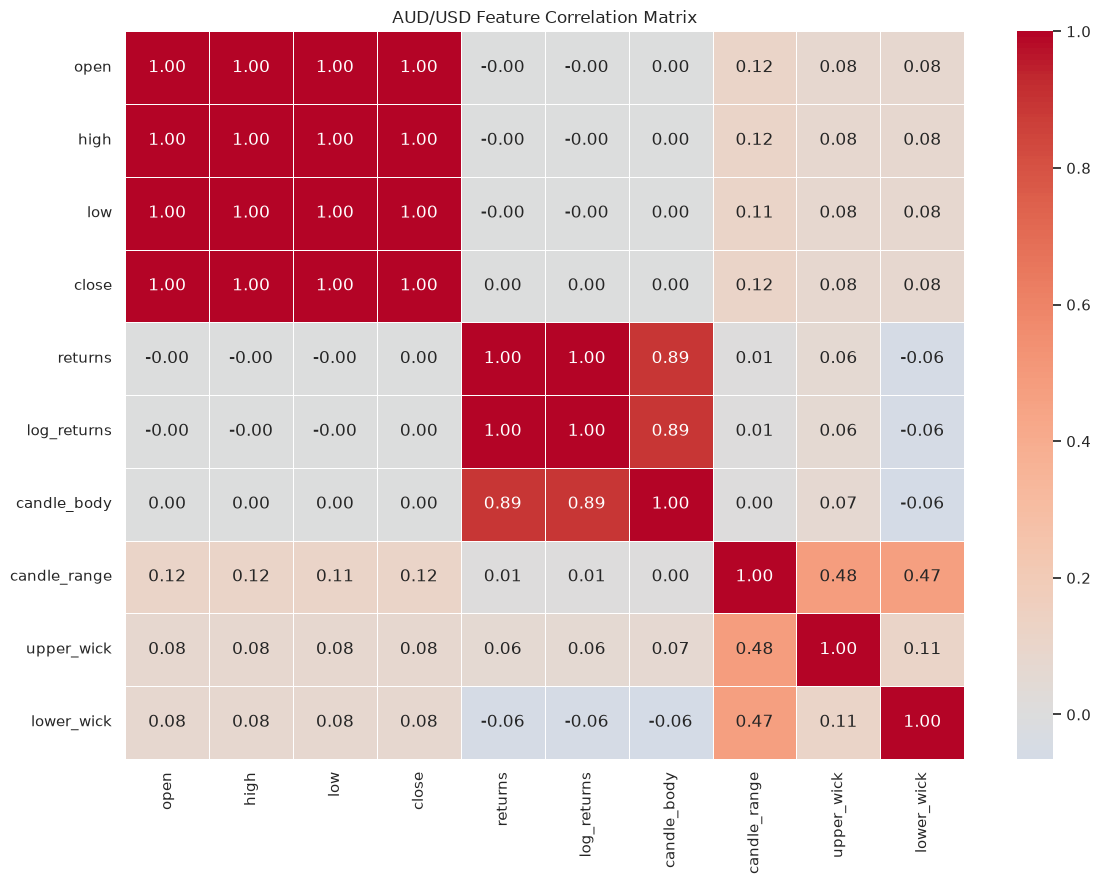

In [80]:
correlation_cols = price_cols + features_aud_usd

corr = df_aud_usd[correlation_cols].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f',
    linewidths=0.5
)

plt.title('AUD/USD Feature Correlation Matrix')
plt.tight_layout()
plt.show()


# Model Creation
The target is a 15-minute forward close return:

$$R_{t+15} = \frac{Close_{t+15}-Close_t}{Close_t}$$

A positive return is **increase**, a negative return is **decrease**, and values inside a configurable basis-point band are **neutral**. Training is chronological to avoid look-ahead leakage.

In [81]:
# adding addtional features for 5,15,30min intervals 
# Multi-period returns
for period in [5, 15, 30]:
    df_eur_usd[f'returns_{period}m'] = (
        df_eur_usd.groupby('pair')['close'].pct_change(period)
    )

# Rolling volatility
df_eur_usd['volatility_15m'] = (
    df_eur_usd.groupby('pair')['log_returns']
    .transform(lambda x: x.rolling(15).std())
)

df_eur_usd['volatility_60m'] = (
    df_eur_usd.groupby('pair')['log_returns']
    .transform(lambda x: x.rolling(60).std())
)

# Moving average ratios
df_eur_usd['sma_ratio_20'] = (
    df_eur_usd['close'] /
    df_eur_usd.groupby('pair')['close']
    .transform(lambda x: x.rolling(20).mean()) - 1
)

df_eur_usd['ema_ratio_50'] = (
    df_eur_usd['close'] /
    df_eur_usd.groupby('pair')['close']
    .transform(lambda x: x.ewm(span=50, adjust=False).mean()) - 1
)

In [82]:
# adding addtional features for 5,15,30min intervals 
# Multi-period returns
for period in [5, 15, 30]:
    df_aud_usd[f'returns_{period}m'] = (
        df_aud_usd.groupby('pair')['close'].pct_change(period)
    )

# Rolling volatility
df_aud_usd['volatility_15m'] = (
    df_aud_usd.groupby('pair')['log_returns']
    .transform(lambda x: x.rolling(15).std())
)

df_aud_usd['volatility_60m'] = (
    df_aud_usd.groupby('pair')['log_returns']
    .transform(lambda x: x.rolling(60).std())
)

# Moving average ratios
df_aud_usd['sma_ratio_20'] = (
    df_aud_usd['close'] /
    df_aud_usd.groupby('pair')['close']
    .transform(lambda x: x.rolling(20).mean()) - 1
)

df_aud_usd['ema_ratio_50'] = (
    df_aud_usd['close'] /
    df_aud_usd.groupby('pair')['close']
    .transform(lambda x: x.ewm(span=50, adjust=False).mean()) - 1
)

In [83]:
from pathlib import Path

MODEL_DIR = Path.cwd() / 'model_output'
MODEL_DIR.mkdir(parents=True, exist_ok=True)

LABEL_NAMES = {-1: 'decrease', 0: 'neutral', 1: 'increase'}


def build_feature_set(df):
    """Add only past-information features and select the model inputs."""
    df = df.copy()
    df['date'] = pd.to_datetime(df['date'], utc=True, errors='coerce')
    df = df.sort_values(['pair', 'date']).drop_duplicates(['pair', 'date'])

    df['lag_return_1'] = df.groupby('pair')['log_returns'].shift(1)
    df['lag_return_5'] = df.groupby('pair')['log_returns'].shift(5)
    df['lag_return_15'] = df.groupby('pair')['log_returns'].shift(15)

    feature_cols = [
        'returns', 'log_returns', 'candle_body', 'candle_range',
        'upper_wick', 'lower_wick', 'returns_5m', 'returns_15m',
        'returns_30m', 'volatility_15m', 'volatility_60m',
        'sma_ratio_20', 'ema_ratio_50', 'lag_return_1',
        'lag_return_5', 'lag_return_15'
    ]
    return df, feature_cols


def train_three_class_model(df, pair_name, neutral_bps=1.0):
    """Train probability models and save the best chronological test model."""
    df, feature_cols = build_feature_set(df)

    # 1 basis point = 0.0001 of relative price. For example, 1 bps means 0.01%.
    neutral_threshold = neutral_bps / 10000.0
    df['future_return_15m'] = (
        df.groupby('pair')['close'].shift(-15) / df['close'] - 1.0
    )
    df['target'] = np.select(
        [df['future_return_15m'] > neutral_threshold,
         df['future_return_15m'] < -neutral_threshold],
        [1, -1],
        default=0
    )

    model_df = df.dropna(subset=feature_cols + ['target', 'future_return_15m']).copy()
    X = model_df[feature_cols]
    y = model_df['target'].astype(int)

    split_index = int(len(model_df) * 0.80)
    X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
    y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

    print(f'{pair_name}: {len(model_df):,} usable rows')
    print('Chronological class distribution:', y.value_counts().sort_index().rename(LABEL_NAMES).to_dict())
    print(f'Train rows: {len(X_train):,} | Test rows: {len(X_test):,}')

    candidates = {
        'logistic': make_pipeline(
            SimpleImputer(strategy='median'),
            StandardScaler(),
            LogisticRegression(
                class_weight='balanced', max_iter=1000, random_state=42
            )
        ),
        'hist_gradient': make_pipeline(
            SimpleImputer(strategy='median'),
            HistGradientBoostingClassifier(
                learning_rate=0.06, max_iter=180, max_leaf_nodes=31,
                l2_regularization=1.0, class_weight='balanced', random_state=42
            )
        ),
    }

    results = {}
    for name, model in candidates.items():
        model.fit(X_train, y_train)
        predicted = model.predict(X_test)
        probabilities = model.predict_proba(X_test)
        results[name] = {
            'model': model,
            'accuracy': accuracy_score(y_test, predicted),
            'balanced_accuracy': balanced_accuracy_score(y_test, predicted),
            'log_loss': log_loss(y_test, probabilities, labels=model.classes_),
        }
        print(f"{name}: accuracy={results[name]['accuracy']:.4f}, "
              f"balanced_accuracy={results[name]['balanced_accuracy']:.4f}, "
              f"log_loss={results[name]['log_loss']:.4f}")

    best_name = min(results, key=lambda name: results[name]['log_loss'])
    best_model = results[best_name]['model']
    predicted = best_model.predict(X_test)

    print(f'Best model: {best_name}')
    print(classification_report(
        y_test, predicted,
        labels=sorted(best_model.classes_),
        target_names=[LABEL_NAMES[label] for label in sorted(best_model.classes_)],
        zero_division=0
    ))
    print('Confusion matrix (rows=true, columns=[decrease, neutral, increase]):')
    print(confusion_matrix(y_test, predicted, labels=[-1, 0, 1]))

    artifact = {
        'pair': pair_name,
        'model': best_model,
        'model_name': best_name,
        'feature_cols': feature_cols,
        'neutral_bps': neutral_bps,
        'classes': sorted(best_model.classes_.tolist()),
        'test_metrics': {
            name: {metric: value for metric, value in metrics.items() if metric != 'model'}
            for name, metrics in results.items()
        },
        'chronological_split': {'train_rows': len(X_train), 'test_rows': len(X_test)},
    }
    model_path = MODEL_DIR / f'{pair_name.lower()}_15m_probability.joblib'
    joblib.dump(artifact, model_path)

    latest_features = X.iloc[-1:].copy()
    latest_proba = best_model.predict_proba(latest_features)[0]
    latest_predictions = {
        'probability_decrease': 0.0,
        'probability_neutral': 0.0,
        'probability_increase': 0.0,
    }
    for label, probability in zip(best_model.classes_, latest_proba):
        latest_predictions[f'probability_{LABEL_NAMES[int(label)]}'] = float(probability)

    print(f'Saved model: {model_path.resolve()}')
    print('Latest 15-minute probability estimate:', latest_predictions)
    return artifact


In [84]:
# Train and evaluate EUR/USD
model_eur_usd = train_three_class_model(df_eur_usd, 'EUR_USD', neutral_bps=1.0)


EUR_USD: 74,735 usable rows
Chronological class distribution: {'decrease': 28108, 'neutral': 17923, 'increase': 28704}
Train rows: 59,788 | Test rows: 14,947
logistic: accuracy=0.3512, balanced_accuracy=0.3928, log_loss=1.0845
hist_gradient: accuracy=0.3685, balanced_accuracy=0.3853, log_loss=1.0967
Best model: logistic
              precision    recall  f1-score   support

    decrease       0.40      0.29      0.34      5595
     neutral       0.29      0.64      0.40      3355
    increase       0.43      0.24      0.31      5997

    accuracy                           0.35     14947
   macro avg       0.37      0.39      0.35     14947
weighted avg       0.39      0.35      0.34     14947

Confusion matrix (rows=true, columns=[decrease, neutral, increase]):
[[1632 2530 1433]
 [ 690 2159  506]
 [1797 2742 1458]]
Saved model: /home/atlas/code/Projects/SERAX_Forex_algo/src/dev/model/model_output/eur_usd_15m_probability.joblib
Latest 15-minute probability estimate: {'probability_decrea

In [85]:
# Train and evaluate AUD/USD (filter the AUD source to remove any EUR contamination)
df_aud_usd_model = df_aud_usd[df_aud_usd['pair'].eq('AUD_USD')].copy()
model_aud_usd = train_three_class_model(df_aud_usd_model, 'AUD_USD', neutral_bps=1.0)


AUD_USD: 650,237 usable rows
Chronological class distribution: {'decrease': 256465, 'neutral': 134725, 'increase': 259047}
Train rows: 520,189 | Test rows: 130,048
logistic: accuracy=0.3177, balanced_accuracy=0.3714, log_loss=1.1030
hist_gradient: accuracy=0.3334, balanced_accuracy=0.3803, log_loss=1.1147
Best model: logistic
              precision    recall  f1-score   support

    decrease       0.43      0.13      0.19     48065
     neutral       0.28      0.85      0.43     33542
    increase       0.43      0.14      0.21     48441

    accuracy                           0.32    130048
   macro avg       0.38      0.37      0.28    130048
weighted avg       0.39      0.32      0.26    130048

Confusion matrix (rows=true, columns=[decrease, neutral, increase]):
[[ 6068 35675  6322]
 [ 2499 28395  2648]
 [ 5691 35894  6856]]
Saved model: /home/atlas/code/Projects/SERAX_Forex_algo/src/dev/model/model_output/aud_usd_15m_probability.joblib
Latest 15-minute probability estimate: {'pro